# Early-Career Developer Salary Prediction

**Mission:** To empower young people with the skills, guidance and opportunities to build successful careers.

**Use case:** A young developer (or their mentor) enters their country, experience, education, company size, work arrangement and role, and gets an estimated annual salary. They use it to negotiate fairly and to decide which skills and roles to aim for.

**Dataset:** Stack Overflow Annual Developer Survey 2025 (https://survey.stackoverflow.co/), 49,191 responses and 172 columns.

**Target:** `ConvertedCompYearly`, annual salary in USD, converted to thousands of USD (`salary_k`).

## 2: Load only the columns we need

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

TARGET_RAW = "ConvertedCompYearly"
FEATURES_NUM = ["WorkExp", "YearsCode"]
FEATURES_CAT = ["Country", "EdLevel", "OrgSize", "RemoteWork", "DevType", "ICorPM"]

use = ["Age", "Employment", TARGET_RAW] + FEATURES_NUM + FEATURES_CAT
raw = pd.read_csv("results.csv", usecols=use, encoding="utf-8-sig")
print(raw.shape)

(49191, 11)


## 3: Filter and clean 

In [18]:
df = raw.copy()
print("Start:", len(df))

df = df[(df["Employment"] == "Employed") &
        (df["Age"].isin(["18-24 years old", "25-34 years old"]))]
print("Employed and under 35:", len(df))

df = df[df[TARGET_RAW].between(5_000, 300_000)]
print("Salary between $5k and $300k:", len(df))

df = df.dropna(subset=FEATURES_NUM + FEATURES_CAT)
print("No missing features:", len(df))

df = df[(df["WorkExp"] <= 15) & (df["YearsCode"] <= 40)]
print("Experience in range:", len(df))

top_countries = df["Country"].value_counts().head(12).index
df = df[df["Country"].isin(top_countries)]
print("Top 12 countries:", len(df))

top_roles = df["DevType"].value_counts().head(9).index
df["DevType"] = df["DevType"].where(df["DevType"].isin(top_roles), "Other")

df["salary_k"] = df[TARGET_RAW] / 1000

# Columns used only for filtering are dropped
df = df.drop(columns=["Age", "Employment", TARGET_RAW]).reset_index(drop=True)

print("\nFinal shape:", df.shape)
df.head()

Start: 49191
Employed and under 35: 16914
Salary between $5k and $300k: 8376
No missing features: 8098
Experience in range: 8036
Top 12 countries: 5317

Final shape: (5317, 9)


,EdLevel,WorkExp,YearsCode,DevType,OrgSize,ICorPM,RemoteWork,Country,salary_k
0,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",8.0,14.0,"Developer, mobile",20 to 99 employees,People manager,Remote,Ukraine,61.256
1,"Associate degree (A.A., A.S., etc.)",2.0,10.0,"Developer, back-end",500 to 999 employees,Individual contributor,"Hybrid (some in-person, leans heavy to flexibi...",Netherlands,104.413
2,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",9.0,15.0,Other,"5,000 to 9,999 employees",Individual contributor,Remote,Ukraine,70.000
3,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",7.0,10.0,"Developer, mobile",20 to 99 employees,Individual contributor,Remote,Ukraine,5.400
4,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",7.0,9.0,"Developer, back-end",100 to 499 employees,Individual contributor,Remote,Ukraine,65.691


## 4: Correlation heatmap

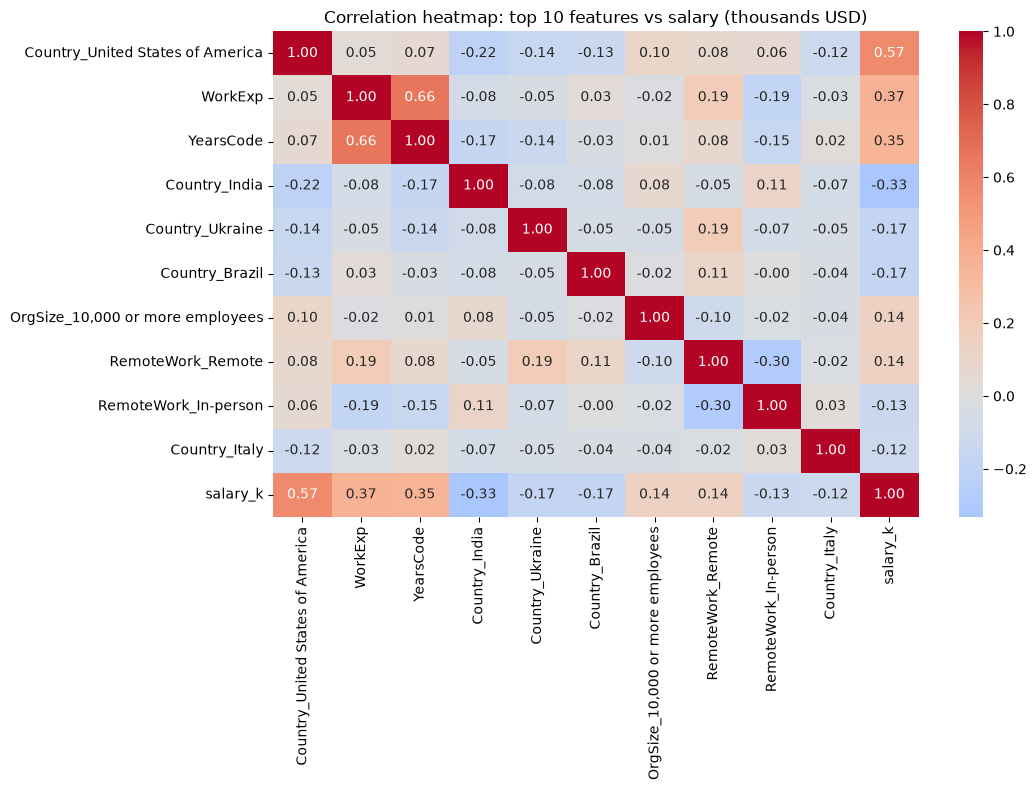

In [14]:
encoded = pd.get_dummies(df, columns=FEATURES_CAT, dtype=float)
corr_with_target = encoded.corr()["salary_k"].drop("salary_k")
top_cols = corr_with_target.abs().sort_values(ascending=False).head(10).index.tolist()

plt.figure(figsize=(11, 8))
sns.heatmap(encoded[top_cols + ["salary_k"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap: top 10 features vs salary (thousands USD)")
plt.tight_layout()
plt.show()

The heatmap shows that where a developer lives matters most for salary, especially being in the USA (higher) or India (lower), followed by years of experience. Company size and remote work have a much weaker link. WorkExp and YearsCode also move together, so I kept an eye on how that overlap affects the linear models. Because of this, I kept Country as a key feature and standardized the numeric columns.

## 5: Histograms of salary and experience

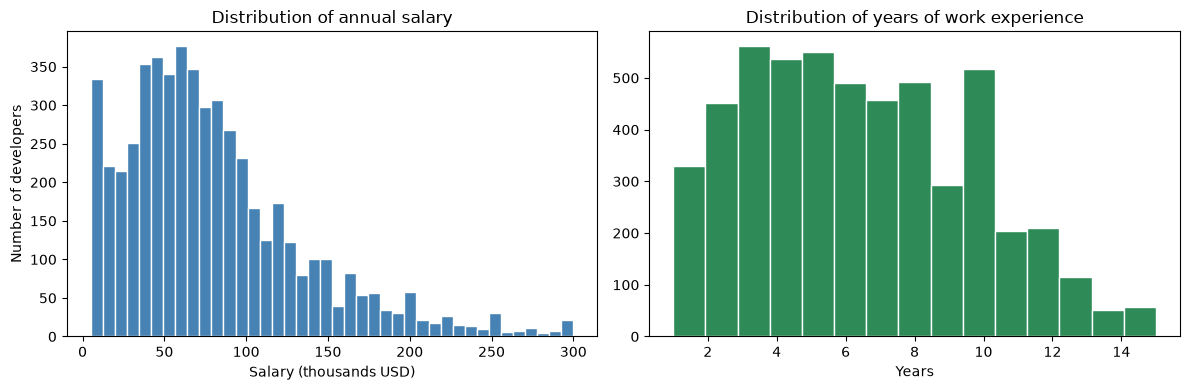

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["salary_k"], bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("Distribution of annual salary")
axes[0].set_xlabel("Salary (thousands USD)")
axes[0].set_ylabel("Number of developers")
axes[1].hist(df["WorkExp"], bins=15, color="seagreen", edgecolor="white")
axes[1].set_title("Distribution of years of work experience")
axes[1].set_xlabel("Years")
plt.tight_layout()
plt.show()

Most developers in this dataset earn under about $100k, but a long tail of high earners stretches the salary distribution to the right. Because a few very high values can dominate the error, I capped salaries at $300k and used thousands of USD as the unit. I’ll also check whether the tree models handle this skew better than the linear ones.

## 6: Median salary by country

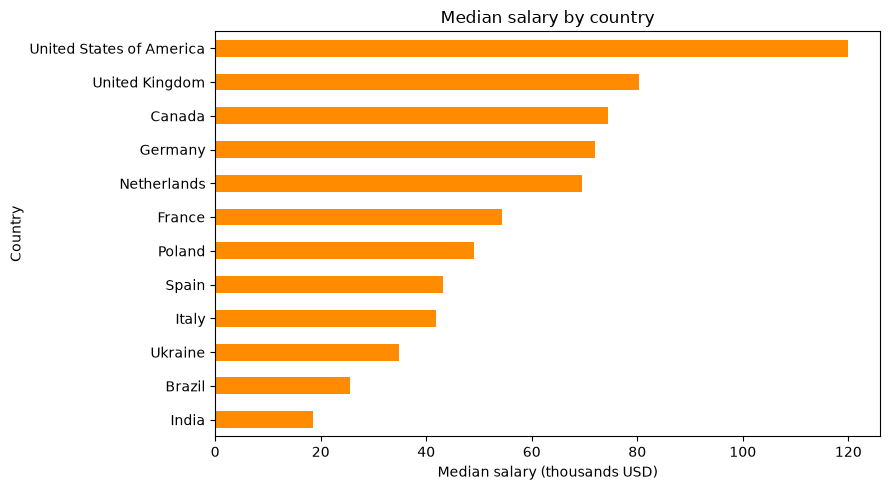

In [16]:
med = df.groupby("Country")["salary_k"].median().sort_values()
med.index = med.index.str.replace(" of Great Britain and Northern Ireland", "", regex=False)
med.plot(kind="barh", figsize=(9, 5), color="darkorange")
plt.xlabel("Median salary (thousands USD)")
plt.title("Median salary by country")
plt.tight_layout()
plt.show()

Pay differs enormously between countries: the median in the USA is roughly six times the median in India. A single number can’t capture that gap, so I one-hot encoded Country. I only kept the 12 countries with enough responses, so the model has enough examples to learn from each one.

## Feature engineering

**Dropped columns and why**
- 160+ survey columns (AI tool questions, technology preferences, job satisfaction, etc.): not available to a young developer when asking "what should I earn?", and many are mostly empty.
- `Age` and `Employment`: used only to keep early-career employed people, so they carry no extra information after filtering.
- `ConvertedCompYearly`: replaced by `salary_k` (the same value in thousands of USD).

**Features kept (8):** `Country`, `WorkExp`, `YearsCode`, `EdLevel`, `OrgSize`, `RemoteWork`, `DevType`, `ICorPM`.

**Which features matter most:** from the heatmap, Country and experience. This will be confirmed with the random forest's feature importances after training.